In [2]:
import soccerdata as sd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator
import warnings
warnings.filterwarnings("ignore")

[10/14/26 14:24:26] INFO     No custom team name replacements found. You can configure these in       ]8;id=13848664;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py\_config.py]8;;\:]8;id=13848665;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py#91\91]8;;\
                             C:\Users\elvin\soccerdata\config\teamname_replacements.json.                          

                    INFO     No custom league dict found. You can configure additional leagues in    ]8;id=13848671;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py\_config.py]8;;\:]8;id=13848672;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py#189\189]8;;\
                             C:\Users\elvin\soccerdata\config\league_dict.json.                                    

In [3]:
season = ["2016/2017","2017/2018", "2018/2019", "2019/2020", "2020/2021", "2021/2022", "2022/2023", "2023/2024", "2024/2025", "2025/2026"]

#hist = sd.MatchHistory(leagues="ENG-Premier League", seasons=season)

In [4]:
#games = hist.read_games()

In [5]:
#games.reset_index(inplace=True)

#games = games[["season", "date", "home_team", "away_team", "home_goals", "away_goals"]]

In [6]:
understat = sd.Understat(seasons=season, leagues="ENG-Premier League")
shots = understat.read_shot_events()

[10/14/26 14:24:30] INFO     Saving cached data to C:\Users\elvin\soccerdata\data\Understat          ]8;id=13848679;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=13848680;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_common.py#250\250]8;;\

[2026-10-14 14:24:30] INFO     TLSLibrary:_load_library:397 - Successfully loaded TLS library: C:\Users\elvin\anaconda3\envs\myenv\Lib\site-packages\tls_requests\bin\tls-client-xgo-1.13.1-windows-amd64.dll


                    INFO     Successfully loaded TLS library:                                      ]8;id=13848687;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\tls_requests\models\libraries.py\libraries.py]8;;\:]8;id=13848688;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\tls_requests\models\libraries.py#397\397]8;;\
                             C:\Users\elvin\anaconda3\envs\myenv\Lib\site-packages\tls_requests\bi                 
                             n\tls-client-xgo-1.13.1-windows-amd64.dll                                             

In [7]:
schedule = understat.read_schedule().reset_index()

In [8]:
goals = shots.reset_index()
goals = goals[goals['result'].isin(["Goal", "Own Goal"])]
goals = goals.merge(schedule[['game_id','home_team', 'away_team']], on="game_id")

In [9]:
og = goals['result'] == 'Own Goal'
goals['scoring_team'] = np.where(~og, goals['team'],
             np.where(goals['team']== goals['home_team'], goals['away_team'], goals['home_team']))


opener = (goals.sort_values(['game_id','minute',"shot_id"]).groupby('game_id').first()[["scoring_team",'minute']]
          .rename(columns={'scoring_team':'first_scorer','minute':"first_goal_min"}))

matches = schedule.merge(opener, on="game_id")
matches['winner'] = np.select([matches['home_goals']>matches['away_goals'], matches['home_goals']<matches['away_goals']],
          [matches['home_team'], matches['away_team']], default=None)

comebacks = matches[matches['winner'].notna() & (matches['first_scorer'] != matches['winner'])]

In [10]:
comebacks[['season','date','home_team','away_team','home_goals','away_goals','first_scorer','winner','first_goal_min']].sort_values(['season','date'])

,season,date,home_team,away_team,home_goals,away_goals,first_scorer,winner,first_goal_min
7,1617,2016-08-14 19:00:00,Arsenal,Liverpool,3,4,Arsenal,Liverpool,30
15,1617,2016-08-20 18:00:00,Watford,Chelsea,1,2,Watford,Chelsea,54
16,1617,2016-08-20 18:00:00,West Bromwich Albion,Everton,1,2,West Bromwich Albion,Everton,8
28,1617,2016-09-10 18:00:00,Arsenal,Southampton,2,1,Southampton,Arsenal,17
35,1617,2016-09-10 18:00:00,West Ham,Watford,2,4,West Ham,Watford,4
...,...,...,...,...,...,...,...,...,...
3499,2526,2026-03-22 12:00:00,Newcastle United,Sunderland,1,2,Newcastle United,Sunderland,9
3507,2526,2026-04-12 13:00:00,Crystal Palace,Newcastle United,2,1,Newcastle United,Crystal Palace,42
3518,2526,2026-04-19 13:00:00,Nottingham Forest,Burnley,4,1,Burnley,Nottingham Forest,46
3551,2526,2026-05-17 15:00:00,Everton,Sunderland,1,3,Everton,Sunderland,42


In [11]:
comebacks.groupby(['season','winner']).size().unstack(fill_value=0).sort_index()

winner,Arsenal,Aston Villa,Bournemouth,Brentford,Brighton,Burnley,Cardiff,Chelsea,Crystal Palace,Everton,...,Sheffield United,Southampton,Stoke,Sunderland,Swansea,Tottenham,Watford,West Bromwich Albion,West Ham,Wolverhampton Wanderers
season,,,,,,,,,,,,,,,,,,,,,
1617,2,0,2,0,0,0,0,4,3,3,...,0,3,0,1,2,4,2,3,2,0
1718,3,0,5,0,0,2,0,2,4,3,...,0,1,2,0,2,3,2,0,1,0
1819,2,0,1,0,1,3,3,2,1,0,...,0,1,0,0,0,3,2,0,3,3
1920,4,2,1,0,1,1,0,2,2,1,...,2,3,0,0,0,4,2,0,1,4
2021,3,2,0,0,1,1,0,3,2,1,...,1,3,0,0,0,4,0,1,4,4
2122,1,1,0,4,2,1,0,2,1,4,...,0,1,0,0,0,4,1,0,4,1
2223,5,1,4,2,2,0,0,2,7,1,...,0,3,0,0,0,4,0,0,2,2
2324,2,4,3,1,3,0,0,3,2,0,...,0,0,0,0,0,7,0,0,5,3
2425,3,4,3,5,5,0,0,4,2,2,...,0,0,0,0,0,3,0,0,0,2


In [12]:
comebacks.groupby('season')['winner'].count()

season
1617    44
1718    43
1819    41
1920    45
2021    56
2122    43
2223    55
2324    54
2425    59
2526    46
Name: winner, dtype: int64

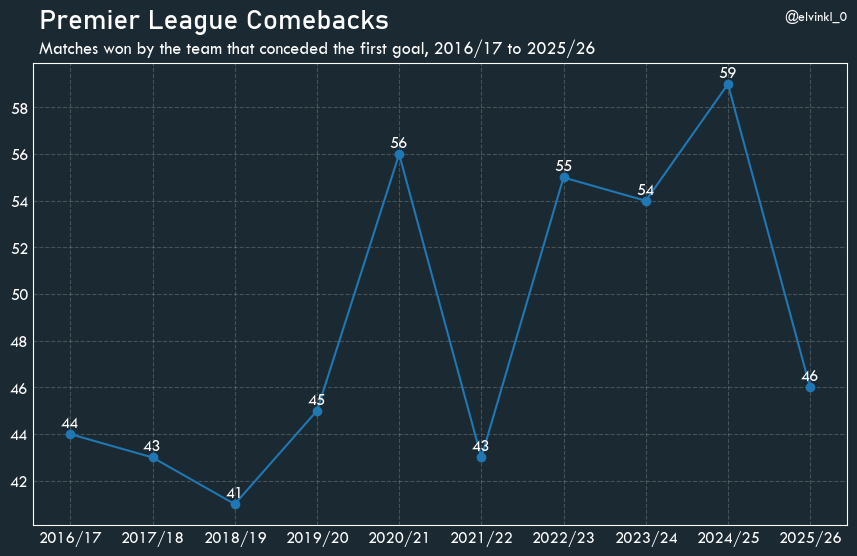

In [13]:
fig, ax = plt.subplots(figsize=(10.5,6))
fig.patch.set_facecolor('#1b2932')
ax.set_facecolor('#1b2932')

cb_per_season = comebacks.groupby('season')['winner'].count().reset_index()
cb_per_season['season'] = '20' + cb_per_season['season'].str[:2] + '/' + cb_per_season['season'].str[2:]
ax.plot(cb_per_season['season'], cb_per_season['winner'], marker='o', color='#1f77b4')

for season, count in zip(cb_per_season['season'], cb_per_season['winner']):
    ax.annotate(str(count), xy=(season, count), xytext=(0, 5), textcoords='offset points', ha='center', color='white', fontfamily='Tw Cen MT', fontsize=12)

#ax.set_xlabel('Season',color='white', fontfamily='Tw Cen MT', fontsize=15)
#ax.set_ylabel('Number of Comebacks', color='white', fontfamily='Tw Cen MT', fontsize=15)
#ax.set_title('Premier League Comebacks', color='white',fontfamily='Bahnschrift', fontsize=30)
fig.text(0.13, 0.97, "Premier League Comebacks", color='white', fontfamily='Bahnschrift', fontsize=20, ha='left', va='top')
fig.text(0.13, 0.92, "Matches won by the team that conceded the first goal, 2016/17 to 2025/26", color='white', fontfamily='Tw Cen MT', fontsize=13, ha='left', va='top')
fig.text(0.9, 0.97, "@elvinkl_0", color='white', fontfamily='Tw Cen MT', fontsize=10, ha='right', va='top')

ax.tick_params(axis='y', colors='white', length=0, labelsize=12, labelfontfamily='Tw Cen MT')
ax.tick_params(axis='x', colors='white', length=0, labelsize=12, labelfontfamily='Tw Cen MT')

ax.yaxis.set_major_locator(MultipleLocator(2))

for spine in ax.spines.values():
    spine.set_color('white')
ax.grid(axis='y',linestyle='--',alpha=0.3)
ax.grid(axis='x',linestyle='--',alpha=0.3)
plt.show()


In [14]:
plt.savefig('pl_comebacks.png', dpi=200, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>